In [33]:
from PIL import Image
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
path = ROOT / "data" / "preprocessed_data" / "corrected.tif"

## Subtracting mean (crude)

(684, 428) (684, 428)


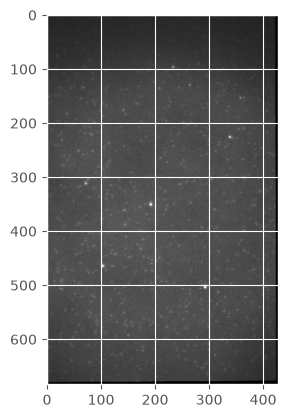

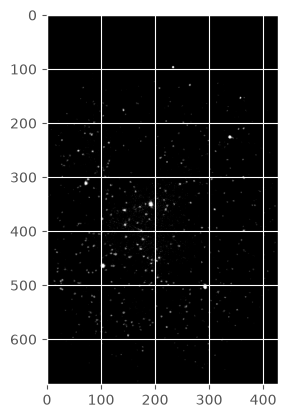

In [48]:
with Image.open(path) as image:
    image.seek(0)
    frame = np.array(image)

left = frame[:, :428]    # columns 0–427
right = frame[:, 428:]  # columns 428–855
print(left.shape, right.shape)  # both (684, 428)
right_centred = np.clip(right.astype(np.float32) - right.mean(), 0, right.max())

plt.imshow(right, cmap="gray", vmin=300, vmax=1500)
plt.show()
plt.imshow(right_centred, cmap="gray", vmin=100, vmax=300)
plt.show()

In [35]:
from picasso.localize import localize_frames

In [36]:
# Detection settings: starting values to explore, not calibrated thresholds.
params = {
    "Box Size": 7,
    "Min. Net Gradient": 1000,
}

# Placeholder camera conversion values for exploring spot positions.
# Replace these with your camera's calibration before interpreting photon counts.
camera_info = {
    "Baseline": 0,
    "Sensitivity": 1.0,
    "Gain": 1,
    "Pixelsize": 117,  # nm; your TIFF metadata says approximately 0.117 µm
}

right_locs = localize_frames(
    right_centred[np.newaxis, :, :],
    info=None,
    params=params,
    camera_info=camera_info,
    fitting_method="gausslq",
    threaded=False,
)

print(f"Right: {len(right_locs)} localisations")

right_locs.head()

Right: 565 localisations


,frame,x,y,photons,sx,sy,bg,lpx,lpy,ellipticity,net_gradient,iterations,chi_square
0,0,280.631134,90.017815,607.603943,1.232871,0.915455,-1.774419,0.066751,0.050602,0.257461,1146.233154,3,1158.439941
385,0,26.208105,491.884705,9398.701172,2.299170,3.783247,24.339874,0.036641,0.059997,0.392276,1840.591309,7,44580.492188
384,0,285.637207,491.876587,1015.938599,1.153813,1.014031,53.158646,0.069077,0.061233,0.121148,1825.834229,3,18605.052734
383,0,50.678219,491.925598,2135.051758,1.445710,1.807967,49.312958,0.058350,0.072464,0.200367,2416.504150,3,11733.178711
382,0,13.930126,492.258392,1234.444092,1.260230,1.096779,70.716080,0.072566,0.063656,0.129699,2609.107910,4,14274.087891


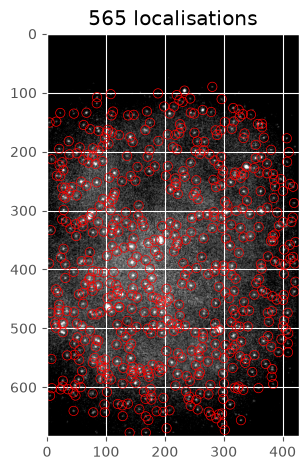

In [37]:
vmin, vmax = np.percentile(right_centred, [1, 99.8])
plt.imshow(right_centred, cmap="gray", vmin=vmin, vmax=vmax)

plt.scatter(
    right_locs["x"], right_locs["y"],
    s=45, facecolors="none", edgecolors="red",
)
plt.title(f"{len(right_locs)} localisations")

plt.tight_layout()
plt.show()

## Subtract a sliding-window median

For each pixel, estimate the background from the current frame and up to 49 preceding frames. The trailing window grows from 1 to 50 frames at the start, so every frame has a median (the first frame subtracts itself). Two heaps per pixel keep the lower and upper halves of the window; Numba compiles the heap updates so this is practical for a whole image. Expired samples are removed immediately, keeping memory bounded.

In [38]:
from numba import njit


@njit
def _sift_down(heap, pixel, pos, size, is_max):
    while 2 * pos + 1 < size:
        child = 2 * pos + 1
        if child + 1 < size:
            if (heap[pixel, child + 1] > heap[pixel, child]) == is_max:
                child += 1
        if (heap[pixel, child] > heap[pixel, pos]) != is_max:
            break
        heap[pixel, pos], heap[pixel, child] = heap[pixel, child], heap[pixel, pos]
        pos = child


@njit
def _sift_up(heap, pixel, pos, is_max):
    while pos > 0:
        parent = (pos - 1) // 2
        if (heap[pixel, pos] > heap[pixel, parent]) != is_max:
            break
        heap[pixel, pos], heap[pixel, parent] = heap[pixel, parent], heap[pixel, pos]
        pos = parent


@njit
def _push(heap, pixel, size, value, is_max):
    heap[pixel, size] = value
    _sift_up(heap, pixel, size, is_max)


@njit
def _remove(heap, pixel, size, value, is_max):
    # Equal values are interchangeable, so removing any matching copy is sufficient.
    pos = 0
    while pos < size and heap[pixel, pos] != value:
        pos += 1
    if pos == size:
        raise ValueError("Expired value missing from heap")
    size -= 1
    if pos < size:
        heap[pixel, pos] = heap[pixel, size]
        if pos > 0 and (heap[pixel, pos] > heap[pixel, (pos - 1) // 2]) == is_max:
            _sift_up(heap, pixel, pos, is_max)
        else:
            _sift_down(heap, pixel, pos, size, is_max)


@njit
def _update_medians(lower, upper, history, values, slot, count, window_size):
    result = np.empty(values.size, dtype=np.float32)
    for pixel in range(values.size):
        n_lower = (count + 1) // 2
        n_upper = count // 2

        if count == window_size:
            old = history[slot, pixel]
            if old <= lower[pixel, 0]:
                _remove(lower, pixel, n_lower, old, True)
                n_lower -= 1
            else:
                _remove(upper, pixel, n_upper, old, False)
                n_upper -= 1

        value = values[pixel]
        if (n_lower > 0 and value <= lower[pixel, 0]) or (
            n_lower == 0 and (n_upper == 0 or value <= upper[pixel, 0])
        ):
            _push(lower, pixel, n_lower, value, True)
            n_lower += 1
        else:
            _push(upper, pixel, n_upper, value, False)
            n_upper += 1

        # The max-heap has either the same number of entries or one more.
        while n_lower > n_upper + 1:
            middle = lower[pixel, 0]
            _remove(lower, pixel, n_lower, middle, True)
            n_lower -= 1
            _push(upper, pixel, n_upper, middle, False)
            n_upper += 1
        while n_lower < n_upper:
            middle = upper[pixel, 0]
            _remove(upper, pixel, n_upper, middle, False)
            n_upper -= 1
            _push(lower, pixel, n_lower, middle, True)
            n_lower += 1

        history[slot, pixel] = value
        if n_lower == n_upper:
            result[pixel] = (lower[pixel, 0] + upper[pixel, 0]) / 2.0
        else:
            result[pixel] = lower[pixel, 0]
    return result


class SlidingWindowMedian:
    """Streaming per-pixel trailing median, including the newest frame."""

    def __init__(self, window_size=50):
        if not isinstance(window_size, int) or window_size < 1:
            raise ValueError("window_size must be a positive integer")
        self.window_size = window_size
        self.count = 0
        self.next_slot = 0
        self.shape = None

    def update(self, frame):
        frame = np.asarray(frame, dtype=np.float32)
        if frame.ndim != 2 or frame.size == 0 or not np.isfinite(frame).all():
            raise ValueError("frame must be a non-empty, finite 2D array")
        if self.shape is None:
            self.shape = frame.shape
            pixels = frame.size
            # One spare heap entry accommodates insertion before rebalancing.
            capacity = (self.window_size + 1) // 2 + 1
            self.lower = np.empty((pixels, capacity), dtype=np.float32)
            self.upper = np.empty((pixels, capacity), dtype=np.float32)
            self.history = np.empty((self.window_size, pixels), dtype=np.float32)
        elif frame.shape != self.shape:
            raise ValueError(f"Expected frame shape {self.shape}, got {frame.shape}")

        median = _update_medians(
            self.lower, self.upper, self.history, frame.ravel(),
            self.next_slot, self.count, self.window_size,
        )
        self.next_slot = (self.next_slot + 1) % self.window_size
        self.count = min(self.count + 1, self.window_size)
        return median.reshape(self.shape)

The comparison below reads up to `comparison_frame` sequentially, retaining only the 50-frame history. It uses the same right-hand image, clipping, detection settings and display scale for both methods. Set `comparison_frame` to an earlier frame to inspect the growing window, or to a later frame to inspect a fully populated window. The first run includes Numba compilation.

In [39]:
comparison_frame = 100  # zero-based; 49 is the first frame with a full window
median_stream = SlidingWindowMedian(window_size=50)

with Image.open(path) as image:
    if not 0 <= comparison_frame < image.n_frames:
        raise ValueError(f"comparison_frame must be between 0 and {image.n_frames - 1}")
    for frame_index in range(comparison_frame + 1):
        image.seek(frame_index)
        comparison_right = np.asarray(image)[:, 428:].astype(np.float32)
        median_background = median_stream.update(comparison_right)

# Match the earlier mean-subtraction cell, including clipping to non-negative values.
mean_subtracted = np.clip(comparison_right - comparison_right.mean(), 0, comparison_right.max())
median_subtracted = np.clip(comparison_right - median_background, 0, comparison_right.max())
print(f"Frame {comparison_frame}: median uses {median_stream.count} frame(s)")

Frame 100: median uses 50 frame(s)


Mean: 601 localisations
Sliding median: 319 localisations


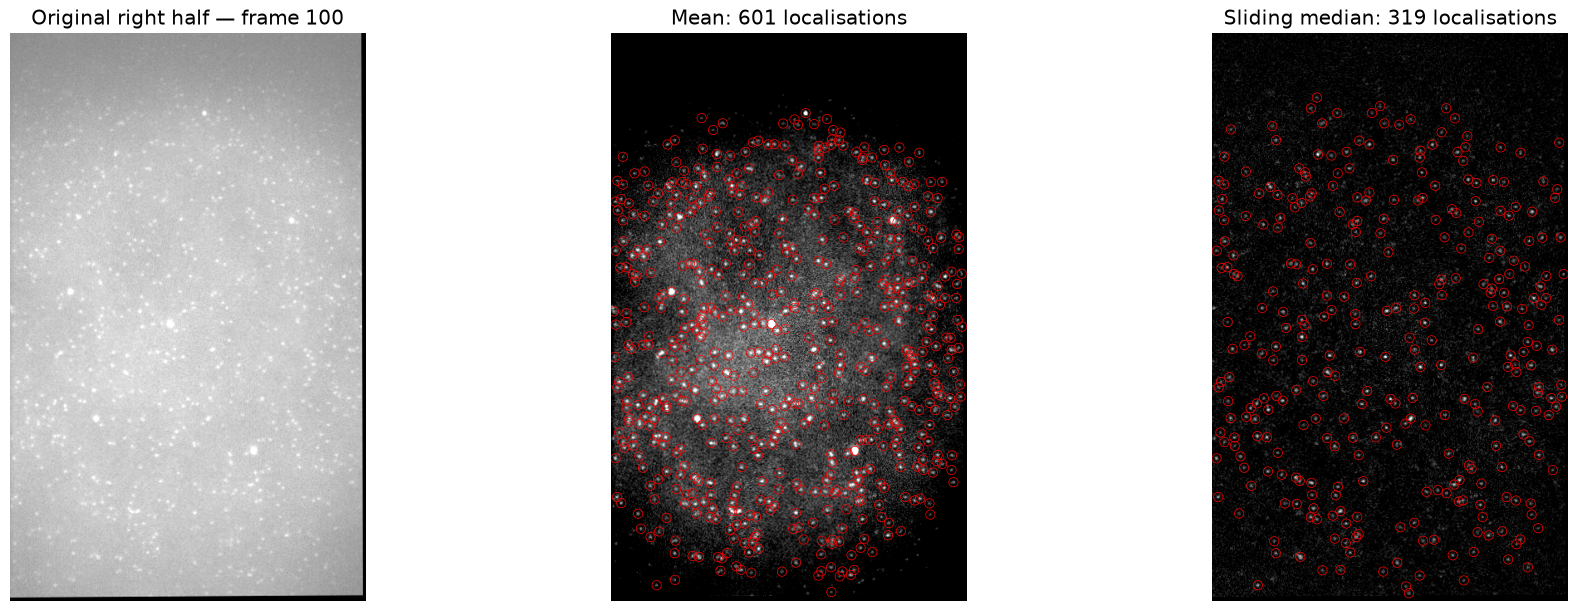

In [40]:
# Apply the same localisation settings to both background-subtracted images.
comparison_locs = {}
for method, corrected in [("Mean", mean_subtracted), ("Sliding median", median_subtracted)]:
    comparison_locs[method] = localize_frames(
        corrected[np.newaxis, :, :],
        info=None,
        params=params,
        camera_info=camera_info,
        fitting_method="gausslq",
        threaded=False,
    )
    print(f"{method}: {len(comparison_locs[method])} localisations")

# Shared limits make the brightness of the two residual images comparable.
display_max = max(np.percentile(mean_subtracted, 99.8),
                  np.percentile(median_subtracted, 99.8), 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
axes[0].imshow(comparison_right, cmap="gray",
               vmin=np.percentile(comparison_right, 1),
               vmax=np.percentile(comparison_right, 99.8))
axes[0].set_title(f"Original right half — frame {comparison_frame}")
for ax, (method, corrected) in zip(
    axes[1:], [("Mean", mean_subtracted), ("Sliding median", median_subtracted)]
):
    ax.imshow(corrected, cmap="gray", vmin=0, vmax=display_max)
    locs = comparison_locs[method]
    ax.scatter(locs["x"], locs["y"], s=45, facecolors="none", edgecolors="red")
    ax.set_title(f"{method}: {len(locs)} localisations")
for ax in axes:
    ax.set_axis_off()
plt.show()

Localisation counts are a visual comparison with the same exploratory threshold, not a measure of accuracy: the two subtraction methods can change the net gradient differently. The temporal median also suppresses features that remain at the same pixel for much of the window.

## Estimate simulation inputs from the right channel

These are **exploratory estimates**, not calibrated DECODE parameters. The temporal median above is a per-pixel estimate in camera counts (ADU), not a binary mask. Below we track the spatial median of that background image over a sample of frames and fit molecules in sampled median-subtracted frames. This is the same right channel and 50-frame trailing window used above. The first recorded statistic is frame `comparison_frame`; only use a full window.

For a quick start, the next cell examines up to 100 additional frames and localises every 10th one. Change the settings to sample more of the recording. It continues the existing `median_stream`, so **rerun the cell beginning `comparison_frame = 100` before rerunning this statistics cell**, or the temporal window would be out of order.

The output is in ADU until real camera conversion values are provided. Median subtraction and clipping, interpolation during preprocessing, the detection threshold, overlapping emitters and fitting error can bias brightness; frame 100 alone is not necessarily representative of the whole experiment.


In [41]:
# Sampling choices (zero-based, inclusive end). More frames give broader coverage but take longer.
stats_additional_frames = 100
stats_localise_stride = 10

if stats_additional_frames < 0 or stats_localise_stride < 1:
    raise ValueError('Use a non-negative additional frame count and a positive stride.')
if median_stream.count < median_stream.window_size:
    raise ValueError('Use a comparison_frame with a full median window (at least 49 for a 50-frame window).')
# This cell consumes the stream. Require the preceding comparison cell to be rerun before repeating it.
if globals().get('_stats_stream_used') is median_stream:
    raise RuntimeError('Rerun the comparison_frame cell to reset the median stream before sampling again.')
_stats_stream_used = median_stream

# Fit in ADU-equivalent units, independent of the placeholder camera_info above.
adu_camera = {'Baseline': 0, 'Sensitivity': 1.0, 'Gain': 1, 'Pixelsize': 117}
background_frames = []
background_levels_adu = []
brightness_samples_adu = []
localisation_counts = []

def record_statistics(index, raw_right, background):
    # One representative background value per frame, robust to isolated bright pixels.
    background_frames.append(index)
    background_levels_adu.append(float(np.median(background)))
    if (index - comparison_frame) % stats_localise_stride == 0:
        residual = np.clip(raw_right - background, 0, raw_right.max())
        locs = localize_frames(residual[np.newaxis, :, :], info=None, params=params,
                               camera_info=adu_camera, fitting_method='gausslq', threaded=False)
        values = np.asarray(locs['photons'], dtype=float)
        valid = values[np.isfinite(values) & (values > 0)]
        brightness_samples_adu.extend(valid.tolist())
        localisation_counts.append((index, len(valid)))

record_statistics(comparison_frame, comparison_right, median_background)
with Image.open(path) as image:
    stats_last_frame = min(comparison_frame + stats_additional_frames, image.n_frames - 1)
    for index in range(comparison_frame + 1, stats_last_frame + 1):
        image.seek(index)
        right_frame = np.asarray(image)[:, 428:].astype(np.float32)
        background = median_stream.update(right_frame)
        record_statistics(index, right_frame, background)
        if (index - comparison_frame) % 25 == 0:
            print(f'Processed frame {index}/{stats_last_frame}')

background_levels_adu = np.asarray(background_levels_adu)
brightness_samples_adu = np.asarray(brightness_samples_adu)
print(f'Background: {len(background_levels_adu)} frames, {comparison_frame}–{stats_last_frame}')
print(f'Brightness: {len(brightness_samples_adu)} positive finite fits from {len(localisation_counts)} sampled frames')
if not len(brightness_samples_adu):
    print('No usable brightness fits; inspect the frame and detection settings.')


Processed frame 125/200
Processed frame 150/200
Processed frame 175/200
Processed frame 200/200
Background: 101 frames, 100–200
Brightness: 3488 positive finite fits from 11 sampled frames


### Results in camera counts (ADU)

The background interval is the **5th–95th percentile across per-frame spatial medians**. The brightness mean and standard deviation describe the fitted, integrated spot signal—not the brightest pixel. These are candidate inputs for exploration; they are not guaranteed to match DECODE’s underlying emitter distribution.


Background spatial median: 675.50 to 693.00 ADU/pixel (5th–95th percentiles over frames)
Background overall range: 675.00 to 693.50 ADU/pixel
Fitted spot brightness: mean 1346.96, sample standard deviation 767.42 ADU-equivalent integrated signal
Fitted spot brightness percentiles (5, 50, 95): [ 575.24 1203.75 2566.42]


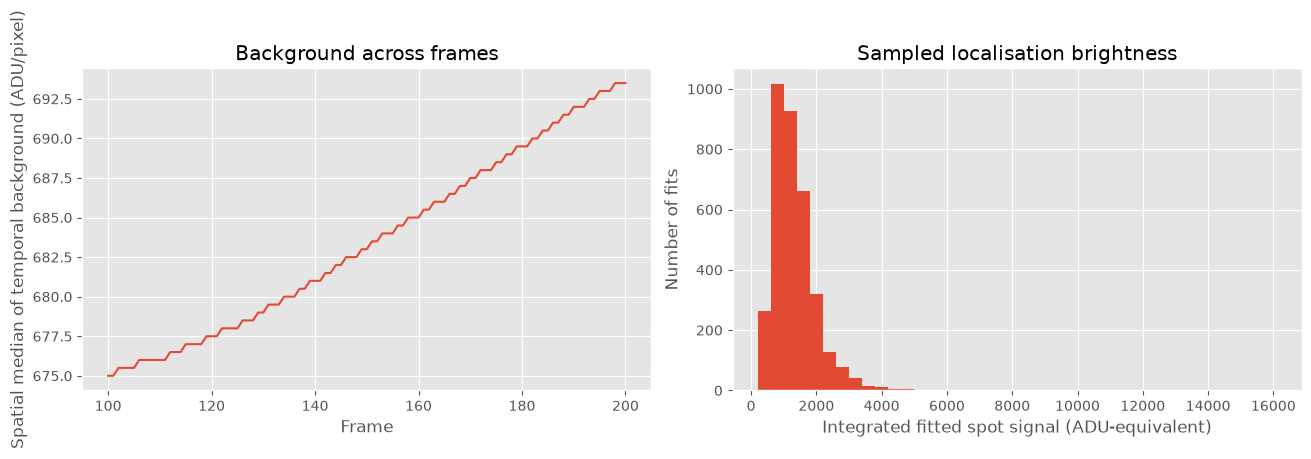

In [42]:
background_range_adu = np.percentile(background_levels_adu, [5, 95])
print(f'Background spatial median: {background_range_adu[0]:.2f} to {background_range_adu[1]:.2f} ADU/pixel (5th–95th percentiles over frames)')
print(f'Background overall range: {background_levels_adu.min():.2f} to {background_levels_adu.max():.2f} ADU/pixel')
if len(brightness_samples_adu):
    brightness_mean_adu = brightness_samples_adu.mean()
    brightness_std_adu = brightness_samples_adu.std(ddof=1) if len(brightness_samples_adu) > 1 else np.nan
    print(f'Fitted spot brightness: mean {brightness_mean_adu:.2f}, sample standard deviation {brightness_std_adu:.2f} ADU-equivalent integrated signal')
    print('Fitted spot brightness percentiles (5, 50, 95):', np.round(np.percentile(brightness_samples_adu, [5, 50, 95]), 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
axes[0].plot(background_frames, background_levels_adu)
axes[0].set(xlabel='Frame', ylabel='Spatial median of temporal background (ADU/pixel)', title='Background across frames')
if len(brightness_samples_adu):
    axes[1].hist(brightness_samples_adu, bins=40)
axes[1].set(xlabel='Integrated fitted spot signal (ADU-equivalent)', ylabel='Number of fits', title='Sampled localisation brightness')
plt.show()


### Optional: convert to DECODE-style photon estimates

For the sCMOS case with no EM gain, DECODE’s camera conversion is approximately `(ADU − baseline) × electrons_per_ADU / quantum_efficiency`, with any spurious-noise term handled according to DECODE’s camera convention. The background has the camera baseline in it; the fitted spot signal was obtained after background subtraction, so **do not subtract the baseline again from brightness**.

Set the values below only after checking the actual camera calibration. `quantum_efficiency = 1` is a detected-photon convention, not a measurement of incident-photon efficiency. The conversion below assumes a scalar gain and no spurious-noise adjustment. Leave the values as `None` to skip it.


In [46]:
camera_baseline_adu = 100.0       # e.g. camera offset in ADU, measured for this acquisition
electrons_per_adu = 0.46         # camera conversion factor, not the placeholder used above
quantum_efficiency = 0.8        # use 1.0 only for the detected-photon convention

if any(x is None for x in (camera_baseline_adu, electrons_per_adu, quantum_efficiency)):
    print('Photon conversion skipped: fill in the camera calibration values above.')
else:
    if electrons_per_adu <= 0 or not 0 < quantum_efficiency <= 1:
        raise ValueError('electrons_per_adu must be positive and quantum_efficiency must be in (0, 1].')
    factor = electrons_per_adu / quantum_efficiency
    background_photons_estimate = (background_range_adu - camera_baseline_adu) * factor
    print('Candidate background_photons (5th–95th percentile):', background_photons_estimate.round(2).tolist(), 'photons/pixel')
    if np.any(background_photons_estimate < 0):
        print('Warning: converted background is negative; check the baseline and assumptions.')
    if len(brightness_samples_adu) >= 2:
        brightness_mean_std_estimate = [float(brightness_samples_adu.mean() * factor),
                                        float(brightness_samples_adu.std(ddof=1) * factor)]
        print('Candidate brightness_mean_std:', np.round(brightness_mean_std_estimate, 2).tolist(), 'photons')
    else:
        print('Need at least two fitted spots for a brightness mean and sample standard deviation.')


Candidate background_photons (5th–95th percentile): [330.91, 340.98] photons/pixel
Candidate brightness_mean_std: [774.5, 441.27] photons


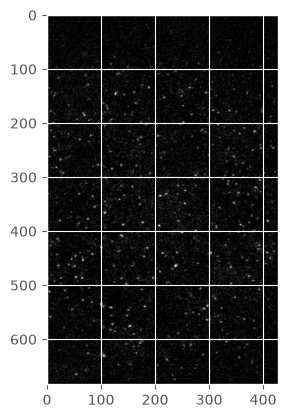

In [58]:
plt.imshow(median_subtracted,cmap="gray", vmin=0, vmax=display_max)